# 08 - Topological data analysis (Mapper and persistent homology)

The applicant feature space is summarised with a **Mapper graph** (Singh, Memoli & Carlsson,
2007) and **persistent homology**. Nodes are overlapping clusters of similar loans; colouring
them by observed outcome and calibration gap shows *where* the model is well or poorly
calibrated. Diagnostics use the **validation** split so the test set stays untouched.
Point clouds are built by `scripts/generate_reports.py` (local, git-ignored).

> Notebooks display **aggregates only** (no individual loan records) and reuse functions from `src/creditiq/`. Educational project - not for real lending decisions.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from creditiq.config import load_config, setup_logging
from creditiq.cli import processed_path, clean_all_path
from creditiq.reporting import figures as figs

setup_logging("WARNING")
cfg = load_config()
figs.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TARGET = cfg["target"]["name"]

In [2]:
from creditiq.reporting.results import tda_cloud_path
from creditiq.tda.point_cloud import feature_matrix, feature_columns
from creditiq.tda.lenses import compute_lens, LENSES
from creditiq.tda.mapper import build_mapper, knn_eps, node_statistics, layout, edge_segments
from creditiq.tda.persistence import persistence_diagrams, diagram_frame, persistence_summary
from creditiq.tda.insights import generate_ideas, STATIC_IDEAS
cloud = pd.read_parquet(tda_cloud_path(cfg.path("processed_dir"), "applicant", "validation"))
X = feature_matrix(cloud)
m = cfg["tda"]["mapper"]
eps = knn_eps(X, k=m["knn_k"], quantile=m["eps_quantile"], seed=cfg.seed)
print(f"{len(cloud):,} loans x {X.shape[1]} standardised features; clustering scale eps = {eps:.2f}")

6,000 loans x 23 standardised features; clustering scale eps = 2.17


## Mapper graph with the model-PD lens

nodes=65 edges=54 components=11 coverage=72.8%


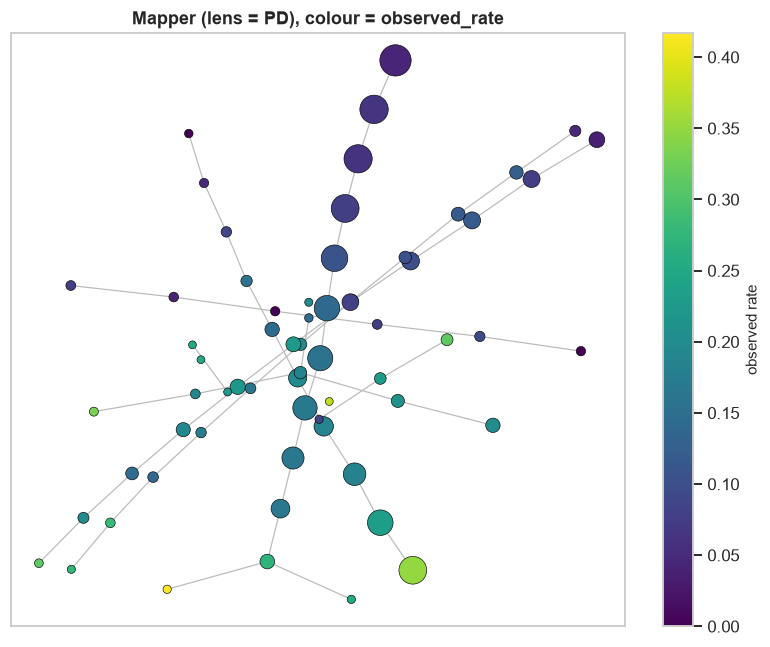

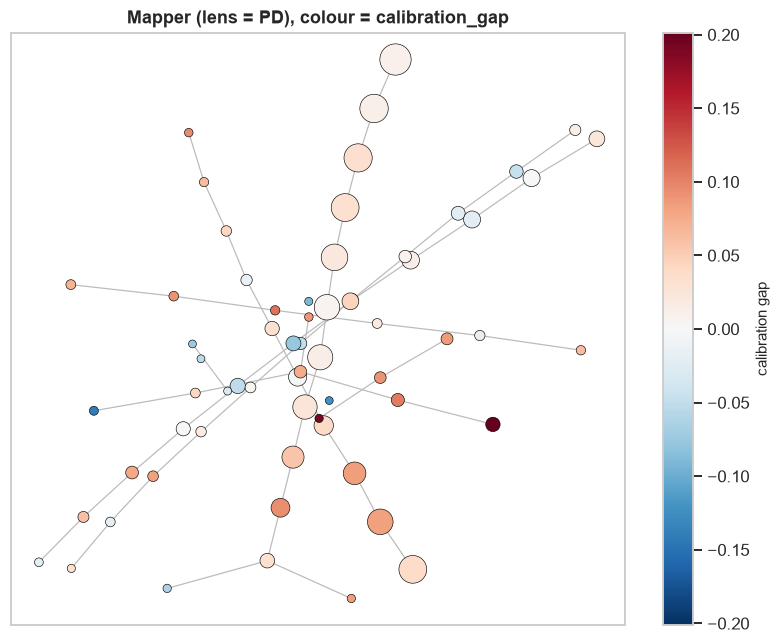

,node_id,size,observed_rate,mean_pd,calibration_gap,gap_z,within_node_auc,profile
60,60,85,0.200000,0.401429,0.201429,5.042338,0.570069,"high term_months (+1.6 sd), high has_major_der..."
54,54,322,0.229814,0.312417,0.082604,4.024649,0.579065,"high term_months (+1.6 sd), high loan_to_incom..."
47,47,246,0.182927,0.266570,0.083643,3.562020,0.484135,"high term_months (+1.6 sd), high loan_amnt (+0..."
48,48,163,0.165644,0.258663,0.093019,3.224523,0.570806,"low log_annual_inc (-1.1 sd), high open_to_tot..."
46,46,235,0.165957,0.223776,0.057818,2.406569,0.487703,"low log_annual_inc (-1.0 sd), low credit_histo..."
57,57,67,0.208955,0.313632,0.104676,2.326416,0.570081,"high term_months (+1.6 sd), high has_major_der..."
63,63,383,0.349869,0.387930,0.038060,2.022420,0.566745,"high term_months (+1.6 sd), high loan_to_incom..."
28,28,94,0.223404,0.147316,-0.076089,-2.003017,0.647750,"high has_major_derog (+1.6 sd), high has_delin..."


In [3]:
graph = build_mapper(X, compute_lens("Model PD (calibrated)", X, cloud), n_intervals=m["n_intervals"],
                     overlap=m["overlap"], eps=eps, min_cluster_size=m["min_cluster_size"])
nodes = node_statistics(graph, cloud, feature_columns(cloud))
pos = layout(graph); seg = edge_segments(graph.edges, pos)
print(f"nodes={len(nodes)} edges={len(graph.edges)} components={graph.n_components} coverage={graph.coverage:.1%}")
for colour in ("observed_rate", "calibration_gap"):
    figs.plot_mapper(nodes, pos, seg, colour, f"Mapper (lens = PD), colour = {colour}"); plt.show()
display(nodes.sort_values("gap_z", key=np.abs, ascending=False).head(8)[["node_id", "size", "observed_rate", "mean_pd", "calibration_gap", "gap_z", "within_node_auc", "profile"]])

## Are the findings robust to the lens and resolution?

In [4]:
rows = []
for lens in LENSES:
    for n_int in (8, 12, 16):
        g = build_mapper(X, compute_lens(lens, X, cloud), n_intervals=n_int, overlap=m["overlap"], eps=eps, min_cluster_size=m["min_cluster_size"])
        st_ = node_statistics(g, cloud, feature_columns(cloud))
        big = st_[st_["size"] >= 60]
        rows.append({"lens": lens, "intervals": n_int, "nodes": len(g.nodes), "components": g.n_components,
                     "coverage": round(g.coverage, 3), "max_abs_gap_z": round(float(big["gap_z"].abs().max()), 2) if len(big) else np.nan})
display(pd.DataFrame(rows))

,lens,intervals,nodes,components,coverage,max_abs_gap_z
0,Model PD (calibrated),8,53,10,0.772,4.76
1,Model PD (calibrated),12,65,11,0.728,5.04
2,Model PD (calibrated),16,81,10,0.694,4.09
3,PCA 1,8,33,10,0.832,4.55
4,PCA 1,12,47,10,0.815,5.15
5,PCA 1,16,57,10,0.805,5.26
6,k-NN density,8,63,11,0.705,2.96
7,k-NN density,12,73,9,0.641,2.96
8,k-NN density,16,84,9,0.592,2.68
9,PD x PCA 1 (2-D),8,162,10,0.748,5.33


## Persistent homology: adverse vs repaid loans

,group,dimension,n_features,total_persistence,max_persistence,median_persistence
0,adverse,H0,599,1328.833485,5.923379,2.095653
1,adverse,H1,619,109.698519,0.851801,0.148819
2,repaid,H0,599,1245.961003,5.274294,1.971031
3,repaid,H1,599,94.942943,0.867815,0.126291


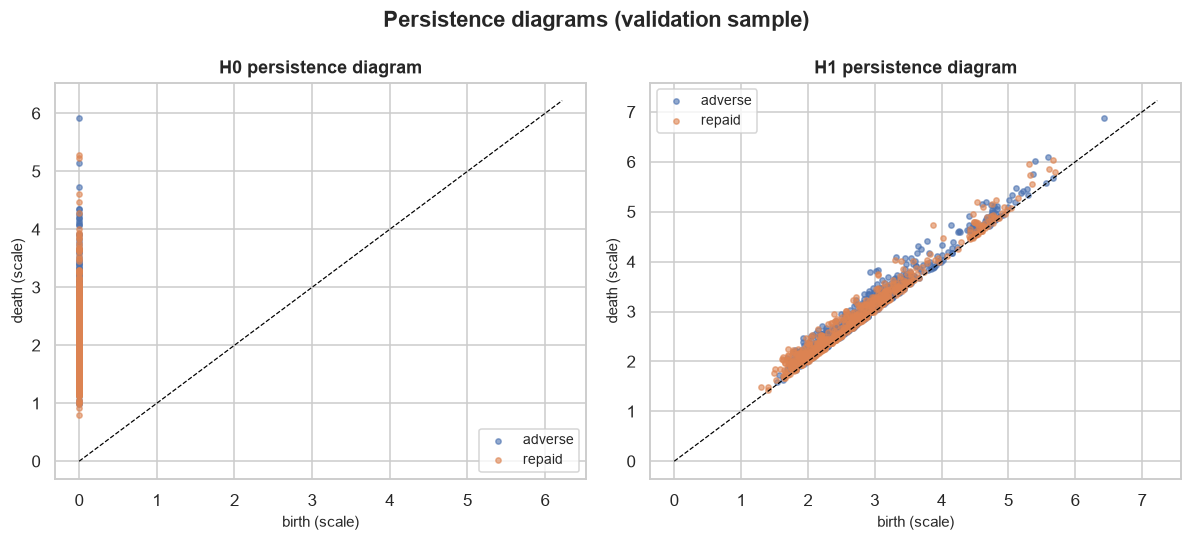

In [5]:
rng = np.random.default_rng(cfg.seed); frames = []
for label, val in (("adverse", 1), ("repaid", 0)):
    idx = rng.choice(np.flatnonzero(cloud["y"].to_numpy() == val), size=cfg["tda"]["persistence_sample"], replace=False)
    frames.append(diagram_frame(persistence_diagrams(X[idx]), label))
dg = pd.concat(frames)
display(persistence_summary(dg))
figs.plot_persistence(dg, "Persistence diagrams (validation sample)"); plt.show()

## Evidence-based improvement ideas

In [6]:
for idea in generate_ideas(nodes, float(cloud["y"].mean()), graph.n_components):
    display(Markdown(f"**{idea['kind']} - {idea['title']}**  \n*Evidence:* {idea['evidence']}  \n*Next step:* {idea['action']}"))
display(Markdown("\n".join(f"- **{t}.** {d}" for t, d in STATIC_IDEAS)))

**Calibration - Model over-predicts risk in node 60**  
*Evidence:* n=85, observed 20.0% vs predicted 40.1% (z=+5.0); profile: high term_months (+1.6 sd), high has_major_derog (+1.6 sd), high has_delinq_history (+0.9 sd).  
*Next step:* Test a segment-aware recalibration or an interaction feature for this profile; first confirm the gap on another period (it may reflect the exclusion of unresolved 60-month loans if share_60m is high).

**Calibration - Model over-predicts risk in node 54**  
*Evidence:* n=322, observed 23.0% vs predicted 31.2% (z=+4.0); profile: high term_months (+1.6 sd), high loan_to_income (+0.8 sd), low has_major_derog (-0.6 sd).  
*Next step:* Test a segment-aware recalibration or an interaction feature for this profile; first confirm the gap on another period (it may reflect the exclusion of unresolved 60-month loans if share_60m is high).

**Calibration - Model over-predicts risk in node 47**  
*Evidence:* n=246, observed 18.3% vs predicted 26.7% (z=+3.6); profile: high term_months (+1.6 sd), high loan_amnt (+0.7 sd), high loan_to_income (+0.7 sd).  
*Next step:* Test a segment-aware recalibration or an interaction feature for this profile; first confirm the gap on another period (it may reflect the exclusion of unresolved 60-month loans if share_60m is high).

**Calibration - Model over-predicts risk in node 48**  
*Evidence:* n=163, observed 16.6% vs predicted 25.9% (z=+3.2); profile: low log_annual_inc (-1.1 sd), high open_to_total_acc (+1.0 sd), low credit_history_months (-0.8 sd).  
*Next step:* Test a segment-aware recalibration or an interaction feature for this profile; first confirm the gap on another period (it may reflect the exclusion of unresolved 60-month loans if share_60m is high).

**High-risk region - High-risk flare at node 63**  
*Evidence:* observed adverse rate 35.0% = 2.2x the sample average (16.2%); n=383; profile: high term_months (+1.6 sd), high loan_to_income (+1.1 sd), low has_major_derog (-0.6 sd).  
*Next step:* Candidate early-warning / manual-review segment; check that the model's ranking inside the region is adequate (within-node AUC) before using it in a policy rule.

...

**Weak discrimination - Model barely ranks loans inside node 0**  
*Evidence:* within-node AUC 0.480 (n=495, adverse 4.2%); profile: high log_annual_inc (+0.7 sd), low has_major_derog (-0.6 sd), low term_months (-0.6 sd).  
*Next step:* The available application fields carry little extra signal here; consider additional data (e.g. bureau scores, payment history, income verification detail) rather than more model complexity.

**Weak discrimination - Model barely ranks loans inside node 47**  
*Evidence:* within-node AUC 0.484 (n=246, adverse 18.3%); profile: high term_months (+1.6 sd), high loan_amnt (+0.7 sd), high loan_to_income (+0.7 sd).  
*Next step:* The available application fields carry little extra signal here; consider additional data (e.g. bureau scores, payment history, income verification detail) rather than more model complexity.

**Weak discrimination - Model barely ranks loans inside node 46**  
*Evidence:* within-node AUC 0.488 (n=235, adverse 16.6%); profile: low log_annual_inc (-1.0 sd), low credit_history_months (-0.8 sd), high open_to_total_acc (+0.7 sd).  
*Next step:* The available application fields carry little extra signal here; consider additional data (e.g. bureau scores, payment history, income verification detail) rather than more model complexity.

**Structure - The loan space splits into 11 disconnected components**  
*Evidence:* At the chosen scale, groups of loans share no members across components.  
*Next step:* Inspect whether components align with product features (e.g. term, purpose); if their risk drivers differ, compare a segmented model against the global one on validation data.

- **Topological drift monitoring.** Build the Mapper graph per vintage and compare node composition and calibration gaps over time; new or vanishing branches signal population shift earlier than global PSI.
- **Mapper-guided segmentation.** Use stable Mapper regions as candidate segments; accept a segmented model only if it beats the global model on a later out-of-time period.
- **Topological features.** Add node-membership or distance-to-high-risk-region features learned on training data only, then re-validate; guard against leakage by fitting the cover on train.
- **Robustness of conclusions.** Treat a region as real only if it persists across lens choices and resolutions (n_intervals, overlap) - the persistence idea applied to Mapper itself.
- **Censoring-aware outcome.** Regions dominated by 60-month loans are most affected by excluding unresolved loans; a survival (time-to-default) target would remove this artefact.